In [1]:
## 1. Setup
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, balanced_accuracy_score,
                             matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)

sns.set_theme(style="whitegrid")
FIGURES_DIR = os.path.join("results", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
RANDOM_STATE = 42

In [2]:
## 2. Load the saved results of both models
with open("../logisticRegression/results/logistic_regression_results.json") as f:
    lr_results = json.load(f)
with open("../randomForestAlgorithm/results/random_forest_notebook_results.json") as f:
    rf_results = json.load(f)

lr_pred_df = pd.read_csv("../logisticRegression/results/logistic_regression_test_predictions.csv")
rf_pred_df = pd.read_csv("../randomForestAlgorithm/results/random_forest_notebook_predictions.csv")

# Both models must have been scored on exactly the same test rows, in the same order
assert len(lr_pred_df) == len(rf_pred_df)
assert (lr_pred_df["y_true"].values == rf_pred_df["y_true"].values).all()

y_test = lr_pred_df["y_true"].values
proba = {"Logistic Regression": lr_pred_df["lr_proba"].values,
         "Random Forest": rf_pred_df["purchase_probability"].values}
best_threshold = {"Logistic Regression": lr_results["best_threshold"],
                  "Random Forest": rf_results["best_threshold"]}

print("Test sessions:", len(y_test), "| purchases:", int(y_test.sum()),
      "| purchase rate = {:.3f}".format(y_test.mean()))
print("LR best params:", lr_results["best_params"])
print("RF best params:", {k.replace("classifier__", ""): v for k, v in rf_results["best_parameters"].items()})

Test sessions: 2441 | purchases: 382 | purchase rate = 0.156
LR best params: {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l1'}
RF best params: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}


In [ ]:
## 3. Test-set metrics
def predict_at(p, threshold):
    # Strictly greater than: this matches sklearn's predict() for the Random Forest, where 12 test sessions
    # have a probability of exactly 0.50 (a 100/100 tree vote) and are assigned to "no purchase"
    return (p > threshold).astype(int)


def metrics_at(y_true, p, threshold):
    pred = predict_at(p, threshold)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "F1-score": f1_score(y_true, pred),
        "MCC": matthews_corrcoef(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, p),
        "PR-AUC": average_precision_score(y_true, p),
    }

rows = {}
for name, p in proba.items():
    rows[(name, "0.50")] = metrics_at(y_test, p, 0.5)
    rows[(name, f"{best_threshold[name]:.2f} (CV-tuned)")] = metrics_at(y_test, p, best_threshold[name])

# Reference point: a model that always predicts the majority class
majority = {"Accuracy": 1 - y_test.mean(), "Balanced accuracy": 0.5, "Precision": 0.0, "Recall": 0.0,
            "F1-score": 0.0, "MCC": 0.0, "ROC-AUC": 0.5, "PR-AUC": y_test.mean()}
rows[("Majority class baseline", "-")] = majority

comparison = pd.DataFrame(rows).T
comparison.index.names = ["Model", "Threshold"]
comparison.round(4)

Accuracy  Balanced accuracy  \
Model                   Threshold                                      
Logistic Regression     0.50               0.8845             0.8473   
                        0.58 (CV-tuned)    0.8853             0.8414   
Random Forest           0.50               0.8964             0.8256   
                        0.52 (CV-tuned)    0.8959             0.8200   
Majority class baseline -                  0.8435             0.5000   

                                         Precision  Recall  F1-score     MCC  \
Model                   Threshold                                              
Logistic Regression     0.50                0.5988  0.7932    0.6824  0.6226   
                        0.58 (CV-tuned)     0.6037  0.7775    0.6796  0.6184   
Random Forest           0.50                0.6525  0.7225    0.6857  0.6250   
                        0.52 (CV-tuned)     0.6546  0.7094    0.6809  0.6196   
Majority class baseline -                   0.0000  0.0000    0.0000  0.0000   

                                         ROC-AUC  PR-AUC  
Model                   Threshold                         
Logistic Regression     0.50              0.9243  0.6832  
                        0.58 (CV-tuned)   0.9243  0.6832  
Random Forest           0.50              0.9249  0.7183  
                        0.52 (CV-tuned)   0.9249  0.7183  
Majority class baseline -                 0.5000  0.1565

In [4]:
# Sanity check: the recomputed numbers must match what each notebook reported
for name, key_05, key_best in [("Logistic Regression", "test_metrics_threshold_0.5", "test_metrics_best_threshold"),
                               ("Random Forest", "test_metrics_threshold_0.50", "test_metrics_best_threshold")]:
    saved = lr_results if name == "Logistic Regression" else rf_results
    for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]:
        assert abs(rows[(name, "0.50")][metric] - saved[key_05][metric]) < 1e-3, (name, metric)
        assert abs(rows[(name, f"{best_threshold[name]:.2f} (CV-tuned)")][metric] - saved[key_best][metric]) < 1e-3, (name, metric)
print("Recomputed metrics match the values saved by both notebooks.")

os.makedirs("results", exist_ok=True)
comparison.round(4).to_csv("results/model_comparison_metrics.csv")

Recomputed metrics match the values saved by both notebooks.


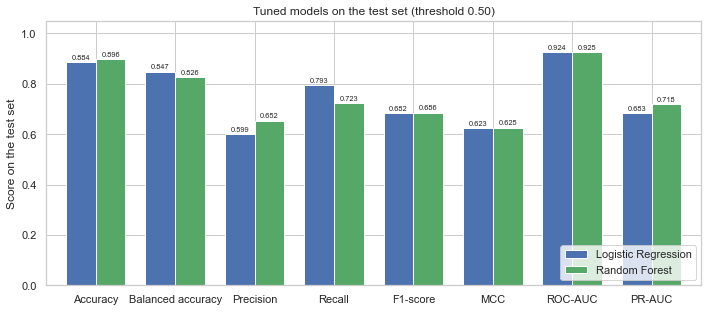

In [5]:
plot_metrics = ["Accuracy", "Balanced accuracy", "Precision", "Recall", "F1-score", "MCC", "ROC-AUC", "PR-AUC"]
bar_df = pd.DataFrame({name: rows[(name, "0.50")] for name in proba})[[*proba]].loc[plot_metrics]

ax = bar_df.plot(kind="bar", figsize=(10, 4.5), color=["#4c72b0", "#55a868"], rot=0, width=0.75)
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.3f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=7.5)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score on the test set")
ax.set_title("Tuned models on the test set (threshold 0.50)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "metric_comparison.png"), dpi=200)
plt.show()

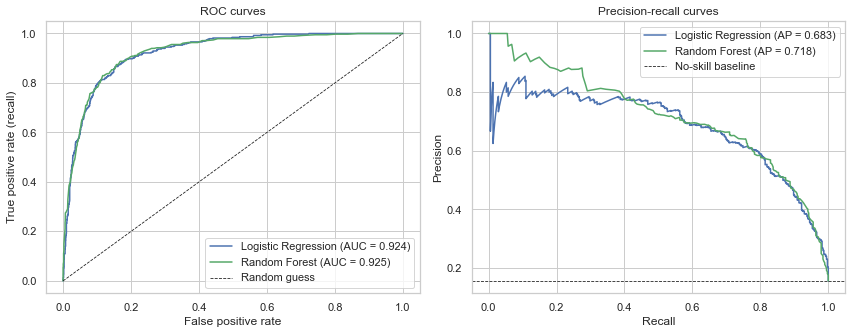

In [ ]:
## 4. ROC and precision-recall curves

colors = {"Logistic Regression": "#4c72b0", "Random Forest": "#55a868"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for name, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=colors[name], label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8, label="Random guess")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves")
axes[0].legend(loc="lower right")

axes[1].axhline(y_test.mean(), color="k", linestyle="--", linewidth=0.8, label="No-skill baseline")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "roc_pr_comparison.png"), dpi=200)
plt.show()

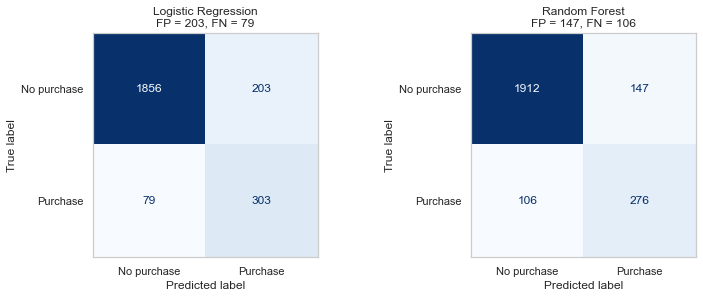

In [ ]:
## 5. Confusion matrices (threshold 0.50)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (name, p) in zip(axes, proba.items()):
    cm = confusion_matrix(y_test, predict_at(p, 0.5))
    ConfusionMatrixDisplay(cm, display_labels=["No purchase", "Purchase"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nFP = {fp}, FN = {fn}")
    ax.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrix_comparison.png"), dpi=200)
plt.show()

In [ ]:
## 6. Is the difference statistically meaningful?

lr_pred = predict_at(proba["Logistic Regression"], 0.5)
rf_pred = predict_at(proba["Random Forest"], 0.5)
lr_correct = lr_pred == y_test
rf_correct = rf_pred == y_test

b = int(np.sum(lr_correct & ~rf_correct))   # LR right, RF wrong
c = int(np.sum(~lr_correct & rf_correct))   # LR wrong, RF right
mcnemar_stat = (abs(b - c) - 1) ** 2 / (b + c)   # with continuity correction
mcnemar_p = chi2.sf(mcnemar_stat, df=1)

print("Both correct:", int(np.sum(lr_correct & rf_correct)), "| both wrong:", int(np.sum(~lr_correct & ~rf_correct)))
print(f"Only LR correct: {b} | only RF correct: {c}")
print(f"McNemar chi-square = {mcnemar_stat:.3f}, p-value = {mcnemar_p:.4f}")

Both correct: 2109 | both wrong: 203
Only LR correct: 50 | only RF correct: 79
McNemar chi-square = 6.078, p-value = 0.0137


In [9]:
rng = np.random.default_rng(RANDOM_STATE)
n_boot = 2000
boot_metrics = {"Accuracy": accuracy_score, "Precision": precision_score, "Recall": recall_score,
                "F1-score": f1_score}
diffs = {m: [] for m in [*boot_metrics, "ROC-AUC", "PR-AUC"]}

p_lr, p_rf = proba["Logistic Regression"], proba["Random Forest"]
for _ in range(n_boot):
    idx = rng.integers(0, len(y_test), len(y_test))
    yt = y_test[idx]
    for m, fn in boot_metrics.items():
        diffs[m].append(fn(yt, rf_pred[idx]) - fn(yt, lr_pred[idx]))
    diffs["ROC-AUC"].append(roc_auc_score(yt, p_rf[idx]) - roc_auc_score(yt, p_lr[idx]))
    diffs["PR-AUC"].append(average_precision_score(yt, p_rf[idx]) - average_precision_score(yt, p_lr[idx]))

boot_summary = pd.DataFrame({
    "RF - LR (observed)": [rows[("Random Forest", "0.50")][m] - rows[("Logistic Regression", "0.50")][m] for m in diffs],
    "95% CI low": [np.percentile(diffs[m], 2.5) for m in diffs],
    "95% CI high": [np.percentile(diffs[m], 97.5) for m in diffs],
}, index=list(diffs))
boot_summary["Interval excludes 0"] = (boot_summary["95% CI low"] > 0) | (boot_summary["95% CI high"] < 0)
boot_summary.round(4)

,RF - LR (observed),95% CI low,95% CI high,Interval excludes 0
Accuracy,0.0119,0.0029,0.0209,True
Precision,0.0537,0.0282,0.0808,True
Recall,-0.0707,-0.1015,-0.0381,True
F1-score,0.0033,-0.0212,0.0283,False
ROC-AUC,0.0006,-0.0077,0.0087,False
PR-AUC,0.0351,-0.0044,0.0732,False


In [ ]:
## 7. Training cost and interpretability

practical = pd.DataFrame({
    "Logistic Regression": {
        "Best hyper-parameters": ", ".join(f"{k}={v}" for k, v in lr_results["best_params"].items()),
        "Best CV F1 (training data)": round(lr_results["cv_best_f1"], 4),
        "Grid size (candidates x 5 folds)": "24 x 5 = 120 fits",
        "Model size": "73 coefficients (8 non-zero after L1)",
        "Interpretation": "Coefficients / odds ratios",
    },
    "Random Forest": {
        "Best hyper-parameters": ", ".join(f"{k.replace('classifier__', '')}={v}"
                                           for k, v in rf_results["best_parameters"].items()),
        "Best CV F1 (training data)": round(rf_results["best_cv_f1"], 4),
        "Grid size (candidates x 5 folds)": "48 x 5 = 240 fits",
        "Model size": "200 fully grown trees",
        "Interpretation": "Impurity / permutation importance",
    },
})
practical

,Logistic Regression,Random Forest
Best hyper-parameters,"C=0.01, class_weight=balanced, penalty=l1","class_weight=balanced, max_depth=None, min_sam..."
Best CV F1 (training data),0.6708,0.6855
Grid size (candidates x 5 folds),24 x 5 = 120 fits,48 x 5 = 240 fits
Model size,73 coefficients (8 non-zero after L1),200 fully grown trees
Interpretation,Coefficients / odds ratios,Impurity / permutation importance


In [ ]:
## 8. Combining the two models (exploratory)

p_avg = (p_lr + p_rf) / 2
ensemble = pd.DataFrame({
    "Logistic Regression": rows[("Logistic Regression", "0.50")],
    "Random Forest": rows[("Random Forest", "0.50")],
    "Average of both (soft vote)": metrics_at(y_test, p_avg, 0.5),
}).T
print("Correlation between the two models' probabilities: {:.3f}".format(np.corrcoef(p_lr, p_rf)[0, 1]))
ensemble.round(4)

Correlation between the two models' probabilities: 0.933


,Accuracy,Balanced accuracy,Precision,Recall,F1-score,MCC,ROC-AUC,PR-AUC
Logistic Regression,0.8845,0.8473,0.5988,0.7932,0.6824,0.6226,0.9243,0.6832
Random Forest,0.8964,0.8256,0.6525,0.7225,0.6857,0.6250,0.9249,0.7183
Average of both (soft vote),0.8845,0.8452,0.5996,0.7880,0.6810,0.6206,0.9313,0.7374
